In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/dataset.csv")

df.head()

,category_1,category_2,category_3,title,product_rating,selling_price,mrp,seller_name,seller_rating,description,highlights,image_links
0,"Sports, Books and More",Sports,Cricket,ITWOSERVICES CRICKET NET 100X10 CRICKET NET NY...,4.4,"₹1,615","₹4,000",I2SERVICES,4.4,NaN,Cricket Practice Net NYLON HDPE Material W x H...,https://rukminim1.flixcart.com/image/612/612/x...
1,"Sports, Books and More",Sports,Cricket,ITWOSERVICES CRICKET NET GROUND BOUNDARY NET 1...,4.4,₹152,₹600,I2SERVICES,4.4,10 X 10 GREEN CRICKET NET HDPE NYLON.,Cricket HDPE NYLON Material W x H x D: 3.048 x...,https://rukminim1.flixcart.com/image/612/612/x...
2,"Sports, Books and More",Sports,Cricket,VICTORY Medium Weight ( Pack of 1 ) Rubber Cri...,3.7,₹59,₹199,VictoryOutlets,4.7,NaN,Cricket Rubber Ball Weight: 110 g,https://rukminim1.flixcart.com/image/612/612/x...
3,"Sports, Books and More",Sports,Cricket,VICTORY Cricket Wind Ball (Pack of 1) - Made i...,3.8,₹75,₹299,VictoryOutlets,4.7,NaN,Cricket Synthetic Ball Weight: 110 g,https://rukminim1.flixcart.com/image/612/612/k...
4,"Sports, Books and More",Sports,Cricket,CEAT Hitman Full Size Double Blade Poplar Cric...,3.4,₹329,"₹1,399",IndiaFit,4.7,The Ceat Poplar Willow Cricket Bat has been de...,Age Group 15+ Yrs Blade Made of Poplar Willow ...,https://rukminim1.flixcart.com/image/612/612/j...


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12041 entries, 0 to 12040
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   category_1      12041 non-null  str    
 1   category_2      12041 non-null  str    
 2   category_3      12041 non-null  str    
 3   title           12023 non-null  str    
 4   product_rating  11961 non-null  float64
 5   selling_price   12013 non-null  str    
 6   mrp             11666 non-null  str    
 7   seller_name     11825 non-null  str    
 8   seller_rating   11827 non-null  float64
 9   description     5021 non-null   str    
 10  highlights      6560 non-null   str    
 11  image_links     12041 non-null  str    
dtypes: float64(2), str(10)
memory usage: 8.0 MB


In [4]:
df.isnull().sum()

category_1           0
category_2           0
category_3           0
title               18
product_rating      80
selling_price       28
mrp                375
seller_name        216
seller_rating      214
description       7020
highlights        5481
image_links          0
dtype: int64

In [5]:
missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_data

,Missing Values,Missing Percentage
category_1,0,0.000000
category_2,0,0.000000
category_3,0,0.000000
title,18,0.149489
product_rating,80,0.664397
selling_price,28,0.232539
mrp,375,3.114359
seller_name,216,1.793871
seller_rating,214,1.777261
description,7020,58.300806


In [6]:
df = df.drop(columns=['description', 'highlights', 'image_links'])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12041 entries, 0 to 12040
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   category_1      12041 non-null  str    
 1   category_2      12041 non-null  str    
 2   category_3      12041 non-null  str    
 3   title           12023 non-null  str    
 4   product_rating  11961 non-null  float64
 5   selling_price   12013 non-null  str    
 6   mrp             11666 non-null  str    
 7   seller_name     11825 non-null  str    
 8   seller_rating   11827 non-null  float64
dtypes: float64(2), str(7)
memory usage: 2.5 MB


In [7]:
df['selling_price'] = (
    df['selling_price']
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
)

df['mrp'] = (
    df['mrp']
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
)

df['selling_price'] = pd.to_numeric(df['selling_price'], errors='coerce')
df['mrp'] = pd.to_numeric(df['mrp'], errors='coerce')

df[['selling_price', 'mrp']].head()

,selling_price,mrp
0,1615.0,4000.0
1,152.0,600.0
2,59.0,199.0
3,75.0,299.0
4,329.0,1399.0


In [8]:
df['discount_percentage'] = (
    (df['mrp'] - df['selling_price']) / df['mrp']
) * 100

df['discount_percentage'] = df['discount_percentage'].round(2)

df[['title', 'selling_price', 'mrp', 'discount_percentage']].head()

,title,selling_price,mrp,discount_percentage
0,ITWOSERVICES CRICKET NET 100X10 CRICKET NET NY...,1615.0,4000.0,59.62
1,ITWOSERVICES CRICKET NET GROUND BOUNDARY NET 1...,152.0,600.0,74.67
2,VICTORY Medium Weight ( Pack of 1 ) Rubber Cri...,59.0,199.0,70.35
3,VICTORY Cricket Wind Ball (Pack of 1) - Made i...,75.0,299.0,74.92
4,CEAT Hitman Full Size Double Blade Poplar Cric...,329.0,1399.0,76.48


In [9]:
print("Selling Price > MRP:", (df['selling_price'] > df['mrp']).sum())
print("Negative Discount:", (df['discount_percentage'] < 0).sum())
print("MRP = 0:", (df['mrp'] == 0).sum())

Selling Price > MRP: 0
Negative Discount: 0
MRP = 0: 0


In [10]:
print("Missing Selling Price:", df['selling_price'].isnull().sum())
print("Missing MRP:", df['mrp'].isnull().sum())

print("\nRows with missing Selling Price or MRP:",
      df[['selling_price', 'mrp']].isnull().any(axis=1).sum())

Missing Selling Price: 28
Missing MRP: 375

Rows with missing Selling Price or MRP: 375


In [11]:
df = df.dropna(subset=['selling_price', 'mrp'])

print("Dataset shape after removing missing price rows:", df.shape)

Dataset shape after removing missing price rows: (11666, 10)


In [12]:
df.isnull().sum()

category_1               0
category_2               0
category_3               0
title                    0
product_rating          60
selling_price            0
mrp                      0
seller_name            183
seller_rating          181
discount_percentage      0
dtype: int64

In [13]:
# Fill missing product ratings with median
df['product_rating'] = df['product_rating'].fillna(
    df['product_rating'].median()
)

# Fill missing seller ratings with median
df['seller_rating'] = df['seller_rating'].fillna(
    df['seller_rating'].median()
)

# Fill missing seller names
df['seller_name'] = df['seller_name'].fillna('Unknown')

# Check missing values
df.isnull().sum()

category_1             0
category_2             0
category_3             0
title                  0
product_rating         0
selling_price          0
mrp                    0
seller_name            0
seller_rating          0
discount_percentage    0
dtype: int64

In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 337


In [15]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (11329, 10)
Remaining duplicates: 0


In [16]:
df.to_csv("../data/cleaned/flipkart_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [17]:
df[['selling_price', 'mrp', 'discount_percentage',
    'product_rating', 'seller_rating']].describe().round(2)

,selling_price,mrp,discount_percentage,product_rating,seller_rating
count,11329.00,11329.00,11329.00,11329.00,11329.00
mean,1633.82,3213.03,54.33,4.06,4.39
std,7379.09,14640.55,21.65,0.34,0.40
min,51.00,65.00,0.00,1.00,3.00
25%,286.00,735.00,40.01,3.90,4.10
50%,439.00,1199.00,58.19,4.10,4.40
75%,790.00,1999.00,71.85,4.30,4.70
max,300490.00,1174131.00,95.55,5.00,5.00


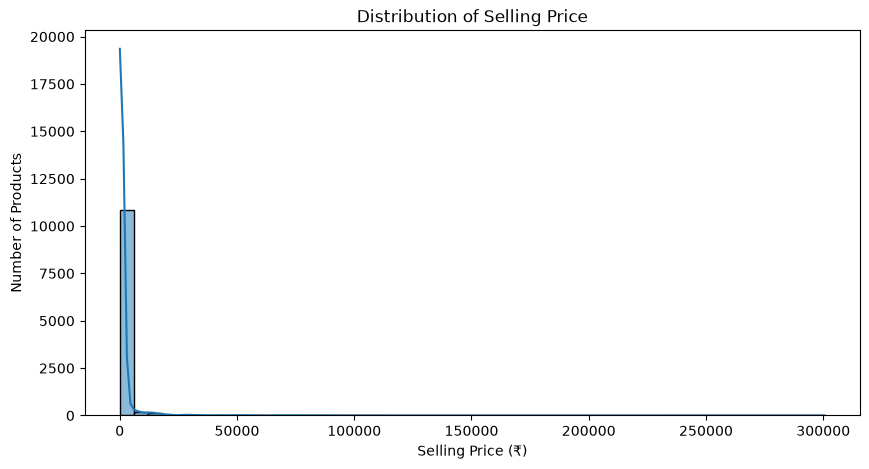

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='selling_price',
    bins=50,
    kde=True
)

plt.title('Distribution of Selling Price')
plt.xlabel('Selling Price (₹)')
plt.ylabel('Number of Products')

plt.show()

In [19]:
# Top 10 most expensive products
df[['title', 'category_1', 'selling_price', 'mrp']].sort_values(
    by='selling_price',
    ascending=False
).head(10)

,title,category_1,selling_price,mrp
2328,DELL Allienware Core i7 12th Gen - (32 GB/1 TB...,Electronics,300490.0,1174131.0
2683,"SONY SEL100400GMC Lens (White, 100 - 400 mm)",Electronics,199690.0,229490.0
2337,APPLE iMac Core i5 (7th Gen) (8 GB DDR4/1 TB/M...,Electronics,189990.0,190400.0
2334,APPLE All-in-One Core i5 (6th Gen) (8 GB DDR3/...,Electronics,180990.0,188900.0
2703,"SONY SEL200600G Lens (White, 200 - 600 mm)",Electronics,154890.0,177990.0
2720,"SONY SEL2470GM Lens (Black, 24 - 70 mm)",Electronics,145290.0,166990.0
2694,"SONY SEL35F14Z Lens (Black, 35 mm)",Electronics,108790.0,117990.0
2695,"ZEISS Loxia 2.4/85 Lens (Black, 85 mm)",Electronics,107909.0,109950.0
2320,ASUS TUF Gaming F15 (2022) Core i7 12th Gen - ...,Electronics,101645.0,137990.0
2338,APPLE iMac Core i5 (5th Gen) (8 GB DDR3/1 TB/M...,Electronics,91490.0,91900.0


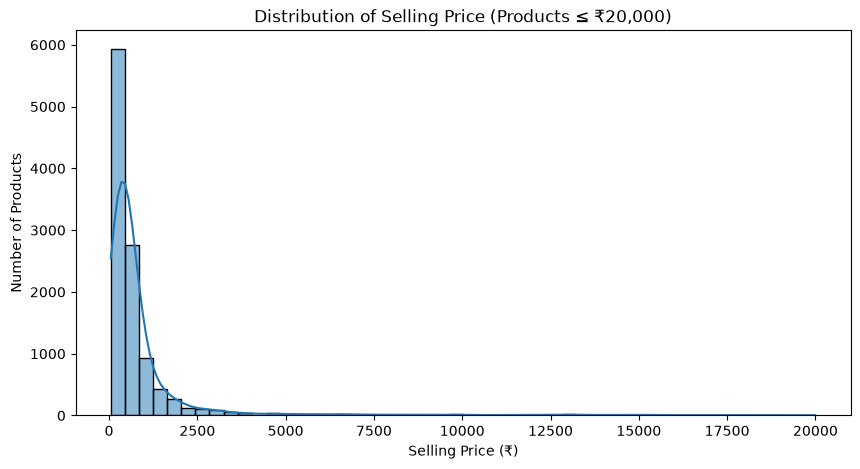

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['selling_price'] <= 20000],
    x='selling_price',
    bins=50,
    kde=True
)

plt.title('Distribution of Selling Price (Products ≤ ₹20,000)')
plt.xlabel('Selling Price (₹)')
plt.ylabel('Number of Products')

plt.show()

In [22]:
category_price = (
    df.groupby('category_1')
    .agg(
        product_count=('title', 'count'),
        average_selling_price=('selling_price', 'mean'),
        median_selling_price=('selling_price', 'median'),
        average_mrp=('mrp', 'mean'),
        average_discount=('discount_percentage', 'mean'),
        average_rating=('product_rating', 'mean')
    )
    .sort_values('average_selling_price', ascending=False)
    .round(2)
)

category_price

,product_count,average_selling_price,median_selling_price,average_mrp,average_discount,average_rating
category_1,,,,,,
Electronics,953,6724.28,799.0,10545.97,51.95,4.12
Home and Furniture,2091,2266.58,529.0,4460.29,53.55,4.04
"Sports, Books and More",1732,1528.50,399.0,3170.18,46.46,4.07
Men's wear,2124,884.83,499.0,2136.68,55.36,4.02
Women's wear,2244,765.44,399.0,1924.11,61.42,4.05
Bady and Kids,2185,511.46,356.0,1225.11,54.07,4.07


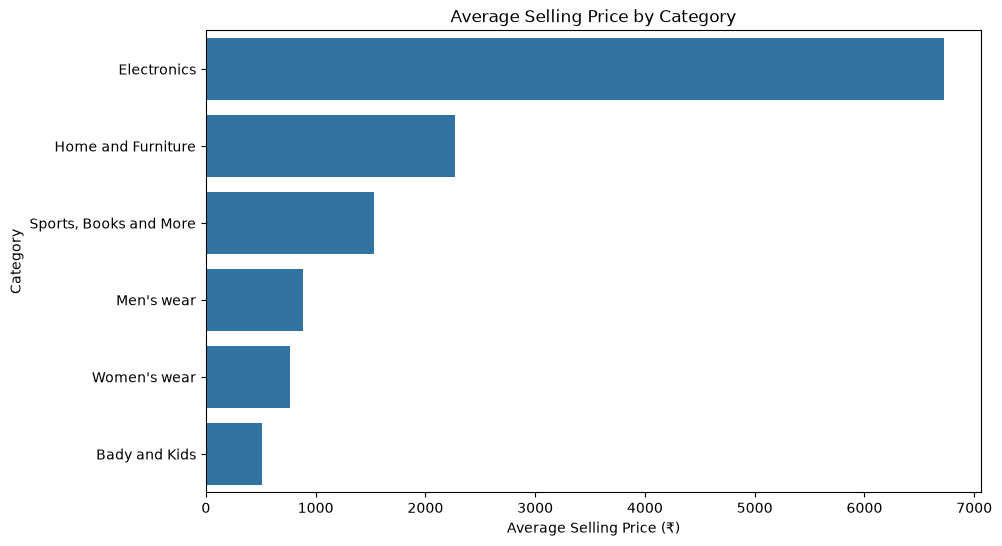

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_price.reset_index(),
    x='average_selling_price',
    y='category_1'
)

plt.title('Average Selling Price by Category')
plt.xlabel('Average Selling Price (₹)')
plt.ylabel('Category')

plt.show()

In [24]:
category_discount = (
    df.groupby('category_1')['discount_percentage']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

category_discount

,category_1,discount_percentage
0,Women's wear,61.422491
1,Men's wear,55.364016
2,Bady and Kids,54.074316
3,Home and Furniture,53.545395
4,Electronics,51.949664
5,"Sports, Books and More",46.460433


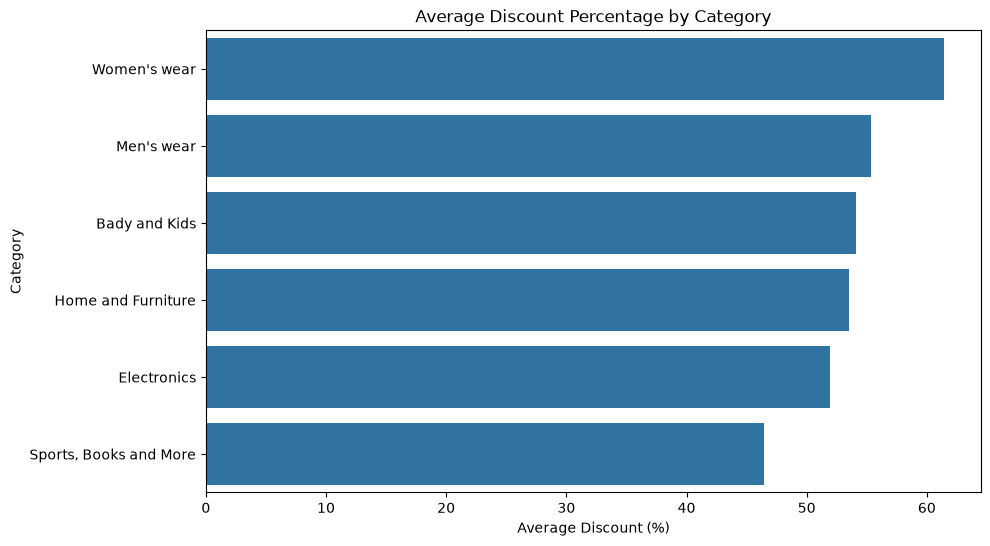

In [26]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_discount,
    x='discount_percentage',
    y='category_1'
)

plt.title('Average Discount Percentage by Category')
plt.xlabel('Average Discount (%)')
plt.ylabel('Category')

plt.show()

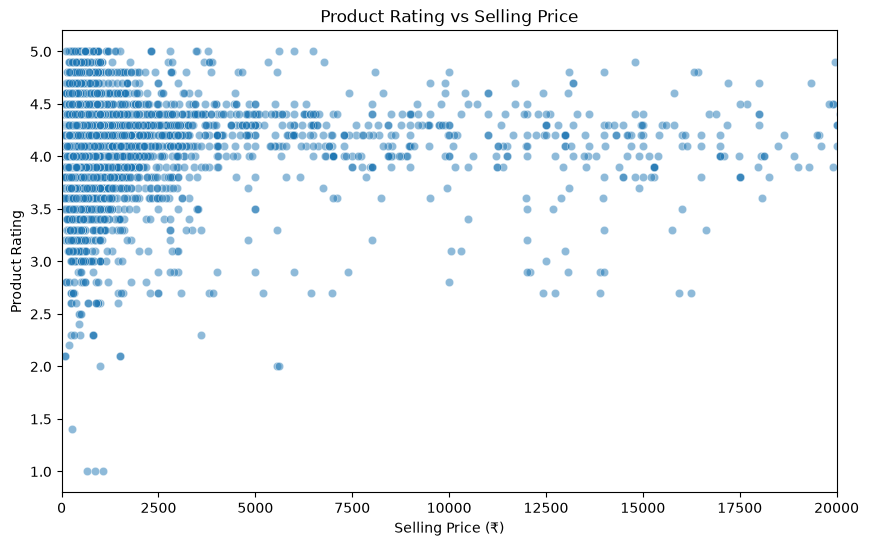

In [27]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='selling_price',
    y='product_rating',
    alpha=0.5
)

plt.xlim(0, 20000)

plt.title('Product Rating vs Selling Price')
plt.xlabel('Selling Price (₹)')
plt.ylabel('Product Rating')

plt.show()

In [28]:
correlation = df['selling_price'].corr(df['product_rating'])

print("Correlation between Selling Price and Product Rating:", round(correlation, 3))

Correlation between Selling Price and Product Rating: 0.099


In [29]:
top_sellers = (
    df.groupby('seller_name')
    .agg(
        product_count=('title', 'count'),
        average_selling_price=('selling_price', 'mean'),
        average_discount=('discount_percentage', 'mean'),
        average_seller_rating=('seller_rating', 'mean')
    )
    .sort_values('product_count', ascending=False)
    .head(10)
    .round(2)
)

top_sellers

,product_count,average_selling_price,average_discount,average_seller_rating
seller_name,,,,
RetailNet,581,4688.62,50.67,4.8
MYTHANGLORYRetail,251,1565.62,34.68,4.9
HSAtlastradeFashion,244,898.29,54.95,4.4
SuperComNet,232,707.50,28.41,4.6
Unknown,178,3592.45,46.76,4.4
SURICYBCOMBazaar,176,470.51,33.90,4.4
DIIATBonline,136,409.12,28.86,4.7
Wizrob Fashion,130,1650.52,30.01,4.7
MTAILMODEECOM,80,3447.68,42.74,4.8


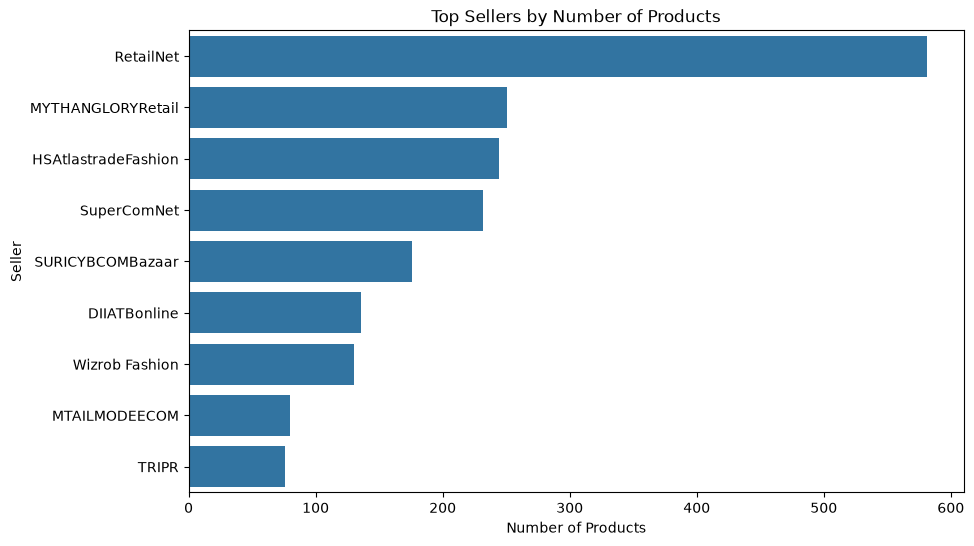

In [30]:
top_sellers_plot = top_sellers.drop('Unknown', errors='ignore').reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_sellers_plot,
    x='product_count',
    y='seller_name'
)

plt.title('Top Sellers by Number of Products')
plt.xlabel('Number of Products')
plt.ylabel('Seller')

plt.show()

In [32]:
# Calculate category-wise average selling price
df['category_avg_price'] = (
    df.groupby('category_1')['selling_price']
    .transform('mean')
)

# Create price segment
df['price_segment'] = 'Average'

df.loc[
    df['selling_price'] < df['category_avg_price'] * 0.75,
    'price_segment'
] = 'Below Average'

df.loc[
    df['selling_price'] > df['category_avg_price'] * 1.25,
    'price_segment'
] = 'Above Average'

# Analyze price segments
price_segment_analysis = (
    df.groupby('price_segment')
    .agg(
        product_count=('title', 'count'),
        average_price=('selling_price', 'mean'),
        average_discount=('discount_percentage', 'mean'),
        average_rating=('product_rating', 'mean')
    )
    .round(2)
)

price_segment_analysis

,product_count,average_price,average_discount,average_rating
price_segment,,,,
Above Average,1574,8564.85,42.69,4.15
Average,1566,897.51,52.95,4.09
Below Average,8189,442.42,56.83,4.03


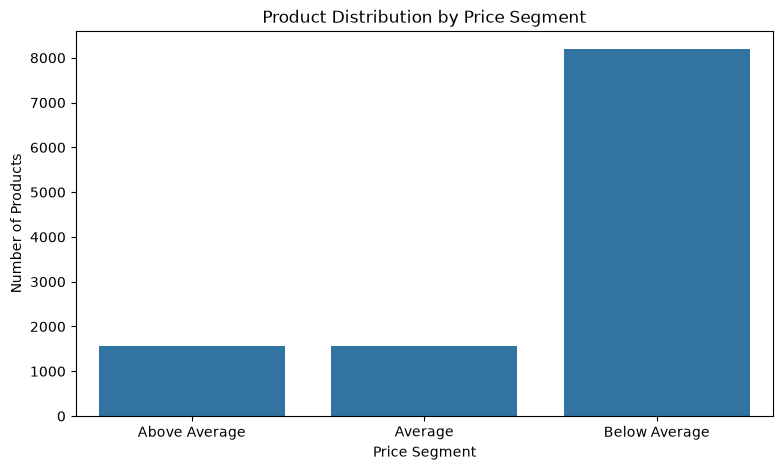

In [33]:
price_segment_plot = (
    price_segment_analysis
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=price_segment_plot,
    x='price_segment',
    y='product_count'
)

plt.title('Product Distribution by Price Segment')
plt.xlabel('Price Segment')
plt.ylabel('Number of Products')

plt.show()

In [34]:
# Remove temporary calculation column
df = df.drop(columns=['category_avg_price'])

# Save final cleaned and enriched dataset
df.to_csv(
    "../data/cleaned/flipkart_price_intelligence.csv",
    index=False
)

print("Final dataset saved successfully!")
print("Final dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Final dataset saved successfully!
Final dataset shape: (11329, 11)

Columns:
['category_1', 'category_2', 'category_3', 'title', 'product_rating', 'selling_price', 'mrp', 'seller_name', 'seller_rating', 'discount_percentage', 'price_segment']
